# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: __________________________    Group: __________    Date: __________

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [2]:
np.random.seed(42)

YearsOfExperience = np.random.randint(2, 21, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

noise = np.random.normal(0, 10000, size=500)

Salary = intercept + slope * YearsOfExperience + noise

df = pd.DataFrame({
    'YearsOfExperience': YearsOfExperience,
    'Salary': Salary
})

display(df.head())

print("Dataset shape:", df.shape)

,YearsOfExperience,Salary
0,8,115037.780010
1,16,182309.972927
2,12,156442.408989
3,9,144753.562169
4,8,130798.818454


Dataset shape: (500, 2)


### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [3]:
print("Dataset shape:", df.shape)

print("\nSummary Statistics:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

correlation = df['YearsOfExperience'].corr(df['Salary'])

print("\nCorrelation:", correlation)

Dataset shape: (500, 2)

Summary Statistics:


,YearsOfExperience,Salary
count,500.000000,500.000000
mean,10.616000,142570.011096
std,5.662922,44935.263058
min,2.000000,54881.134555
25%,5.750000,104426.300731
50%,10.000000,139865.032545
75%,16.000000,182341.125962
max,20.000000,241879.376204



Missing Values:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation: 0.975058457607618


### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

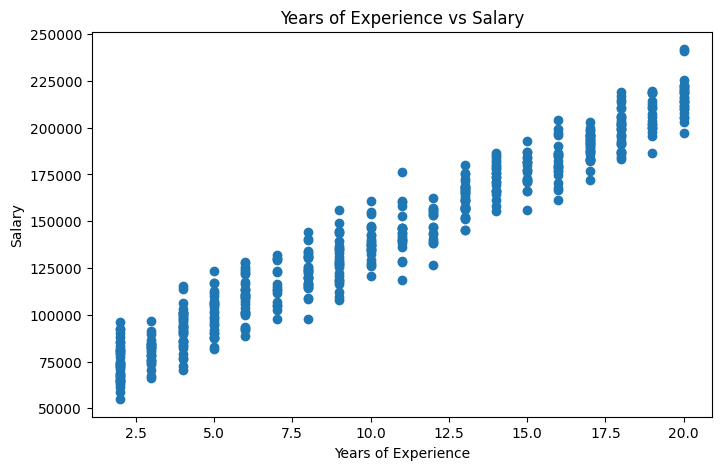

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(df['YearsOfExperience'], df['Salary'])

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Years of Experience vs Salary')

plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [5]:
X = df[['YearsOfExperience']]
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [6]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Slope:", lr_model.coef_[0])
print("Intercept:", lr_model.intercept_)

train_r2 = lr_model.score(X_train, y_train)
test_r2 = lr_model.score(X_test, y_test)

print("Training R2:", train_r2)
print("Testing R2:", test_r2)

Slope: 7696.612923052044
Intercept: 60961.340880280564
Training R2: 0.9488372177019488
Testing R2: 0.9573704756930141


### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [7]:
y_pred = lr_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

results = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

display(results.head())

MAE: 7905.114728709239
MSE: 93933277.37947103
RMSE: 9691.918147584152
R2: 0.9573704756930141


,Actual Salary,Predicted Salary
0,123631.230350,107141.018419
1,139775.630647,122534.244265
2,93184.812446,107141.018419
3,166740.803478,161017.308880
4,174587.183981,184107.147649


### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [8]:
baseline_prediction = y_train.mean()

baseline_pred = np.full(len(y_test), baseline_prediction)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)

print("Baseline MAE:", baseline_mae)
print("Linear Regression MAE:", mae)

print("\nBaseline RMSE:", baseline_rmse)
print("Linear Regression RMSE:", rmse)

Baseline MAE: 40444.95787424255
Linear Regression MAE: 7905.114728709239

Baseline RMSE: 46953.769510036946
Linear Regression RMSE: 9691.918147584152


### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

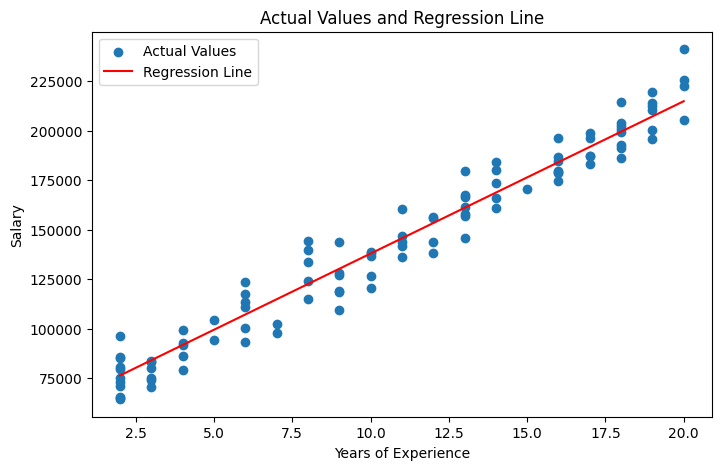

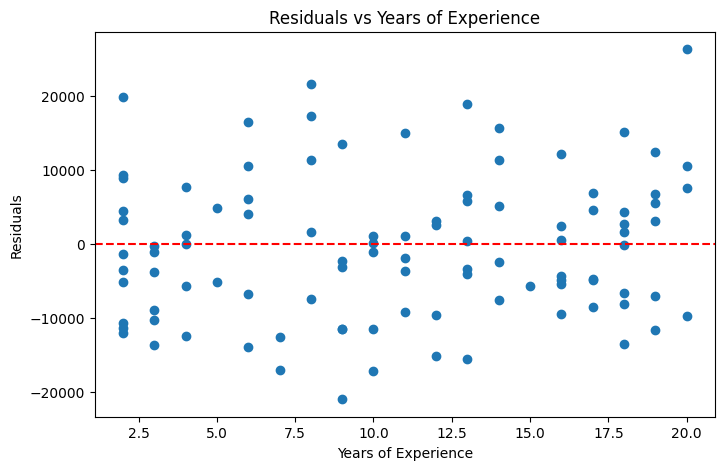

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, label='Actual Values')

X_sorted = X_test.sort_values(by='YearsOfExperience')

y_line = lr_model.predict(X_sorted)

plt.plot(X_sorted, y_line, color='red', label='Regression Line')

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Actual Values and Regression Line')
plt.legend()

plt.show()

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(X_test['YearsOfExperience'], residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Years of Experience')
plt.ylabel('Residuals')
plt.title('Residuals vs Years of Experience')

plt.show()

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [13]:
new_experience = pd.DataFrame({
    'YearsOfExperience': [5, 10, 15]
})

new_predictions = lr_model.predict(new_experience)

new_results = pd.DataFrame({
    'YearsOfExperience': [5, 10, 15],
    'Predicted Salary': new_predictions
})

display(new_results)

,YearsOfExperience,Predicted Salary
0,5,99444.405496
1,10,137927.470111
2,15,176410.534726


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

Scaled Training Data:
[[ 1.14441709]
 [-0.45865743]
 [ 0.07570074]
 [-1.52737378]
 [-1.171135  ]]

Scaled Testing Data:
[[-0.81489621]
 [-0.45865743]
 [-0.81489621]
 [ 0.43193952]
 [ 0.9662977 ]]


### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [15]:
ridge_10 = Ridge(alpha=10)
ridge_100 = Ridge(alpha=100)

ridge_10.fit(X_train_scaled, y_train)
ridge_100.fit(X_train_scaled, y_train)

ridge_10_pred = ridge_10.predict(X_test_scaled)

ridge_100_pred = ridge_100.predict(X_test_scaled)

print("Ridge alpha=10")
print("Coefficient:", ridge_10.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, ridge_10_pred))
print("Test R2:", r2_score(y_test, ridge_10_pred))

print("\n--------------------------")

print("Ridge alpha=100")
print("Coefficient:", ridge_100.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, ridge_100_pred))
print("Test R2:", r2_score(y_test, ridge_100_pred))

print("\nCoefficient Comparison:")
print("Ridge alpha=10:", ridge_10.coef_[0])
print("Ridge alpha=100:", ridge_100.coef_[0])

Ridge alpha=10
Coefficient: 42156.50310768269
Test MAE: 8084.461347657729
Test R2: 0.9557273924644272

--------------------------
Ridge alpha=100
Coefficient: 34568.33254829981
Test MAE: 11308.369993936485
Test R2: 0.9118378157040179

Coefficient Comparison:
Ridge alpha=10: 42156.50310768269
Ridge alpha=100: 34568.33254829981


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [16]:
lasso_1000 = Lasso(alpha=1000, max_iter=20000)
lasso_10000 = Lasso(alpha=10000, max_iter=20000)
lasso_50000 = Lasso(alpha=50000, max_iter=20000)

lasso_1000.fit(X_train_scaled, y_train)
lasso_10000.fit(X_train_scaled, y_train)
lasso_50000.fit(X_train_scaled, y_train)

lasso_1000_pred = lasso_1000.predict(X_test_scaled)
lasso_10000_pred = lasso_10000.predict(X_test_scaled)
lasso_50000_pred = lasso_50000.predict(X_test_scaled)

print("Lasso alpha=1000")
print("Coefficient:", lasso_1000.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, lasso_1000_pred))
print("Test R2:", r2_score(y_test, lasso_1000_pred))

print("\n--------------------------")

print("Lasso alpha=10000")
print("Coefficient:", lasso_10000.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, lasso_10000_pred))
print("Test R2:", r2_score(y_test, lasso_10000_pred))

print("\n--------------------------")

print("Lasso alpha=50000")
print("Coefficient:", lasso_50000.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, lasso_50000_pred))
print("Test R2:", r2_score(y_test, lasso_50000_pred))

print("\nCoefficient Comparison:")
print("Alpha=1000:", lasso_1000.coef_[0])
print("Alpha=10000:", lasso_10000.coef_[0])
print("Alpha=50000:", lasso_50000.coef_[0])

Lasso alpha=1000
Coefficient: 42210.415685374755
Test MAE: 8074.651462959587
Test R2: 0.9558378005043271

--------------------------
Lasso alpha=10000
Coefficient: 33210.41568537476
Test MAE: 12287.962687167314
Test R2: 0.8980447982632193

--------------------------
Lasso alpha=50000
Coefficient: 0.0
Test MAE: 40444.95787424255
Test R2: -0.0005342009730120445

Coefficient Comparison:
Alpha=1000: 42210.415685374755
Alpha=10000: 33210.41568537476
Alpha=50000: 0.0


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [17]:
baseline_r2 = r2_score(y_test, baseline_pred)

ridge_mae = mean_absolute_error(y_test, ridge_10_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_10_pred))
ridge_r2 = r2_score(y_test, ridge_10_pred)

lasso_mae = mean_absolute_error(y_test, lasso_1000_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_1000_pred))
lasso_r2 = r2_score(y_test, lasso_1000_pred)

comparison = pd.DataFrame({
    'Model': [
        'Mean Baseline',
        'Linear Regression',
        'Ridge (alpha=10)',
        'Lasso (alpha=1000)'
    ],

    'MAE': [
        baseline_mae,
        mae,
        ridge_mae,
        lasso_mae
    ],

    'RMSE': [
        baseline_rmse,
        rmse,
        ridge_rmse,
        lasso_rmse
    ],

    'R2': [
        baseline_r2,
        r2,
        ridge_r2,
        lasso_r2
    ]
})

display(comparison.round(2))

,Model,MAE,RMSE,R2
0,Mean Baseline,40444.96,46953.77,-0.00
1,Linear Regression,7905.11,9691.92,0.96
2,Ridge (alpha=10),8084.46,9876.93,0.96
3,Lasso (alpha=1000),8074.65,9864.61,0.96


**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.